# Exercice 2 — Impact des inondations pour une tempête de la bibliothèque de cartes d'inondation — Moroni, Comores

La prévision UFFIS pour les Comores ne lance pas de modèle hydraulique à l'approche
d'une tempête. Chacune des 55 communes ADM3 dispose au contraire d'une **bibliothèque
de 200 tempêtes synthétiques**, chacune accompagnée d'une carte de profondeur maximale
d'inondation précalculée, et la prévision y puise. Ce notebook ouvre la bibliothèque de
**Moroni** — la capitale, sur la Grande Comore —, en extrait une tempête et détermine ce
que son inondation touche réellement : la hauteur d'eau atteinte sur chaque bâtiment et
chaque route, et le nombre de personnes, la surface de plancher et les kilomètres de
route que cela représente au total.

La question posée est la suivante :

> **Dans la tempête 150, quelle est la hauteur d'eau sur chaque bâtiment et chaque route de Moroni ?**

La profondeur est une grandeur physique : la réponse n'a donc besoin d'aucun seuil de
référence — contraste intéressant avec l'exercice 3, qui travaille à partir de
*probabilités* issues d'une prévision et en exige donc un. La section 9 montre comment
les deux se relient, et pour les Comores cela peut être vérifié par rapport au produit
publié plutôt que simplement décrit.

**Ce qui est propre aux Comores**

- **Pluvial uniquement.** Les modèles insulaires ont été exécutés avec un forçage
  pluviométrique et sans débit entrant en limite amont : `hazards_enabled` dans le
  résumé d'exécution indique donc `pluvial: true, fluvial: false`. L'inondation est ici
  de la pluie qui ne s'est pas écoulée, jamais une rivière en crue.
- **Une grille projetée.** Tout est en EPSG:5629 (Moznet / UTM zone 38S) à 30,57 m. Les
  cellules sont en mètres carrés : les surfaces ne demandent donc aucune correction de
  latitude — contrairement aux grilles en secondes d'arc utilisées pour Antigua-et-Barbuda.
- **La profondeur ne sature pas.** Les bibliothèques comoriennes stockent des mètres en
  virgule flottante avec une précision de 1 cm : les tranches profondes veulent donc
  bien dire ce qu'elles disent. Les bibliothèques d'Antigua-et-Barbuda et de la Barbade
  compriment la profondeur sur un octet et plafonnent à 2,55 m.

**Ce qu'il faut en retenir**

- comment lire une seule tranche d'un grand magasin Zarr sans charger tout le tableau
- comment échantillonner un raster sur des dizaines de milliers de polygones en une
  seule passe, pourquoi le *maximum* sur une emprise est le choix défendable, et comment
  repérer qu'une méthode d'échantillonnage n'est pas adaptée à la grille
- d'où vient chaque chiffre d'un tableau d'impact, et quelles décisions en cours de route
  le modifient
- comment une prévision transforme une bibliothèque de scénarios en rasters de
  probabilité de l'exercice 3 — et comment vérifier que la règle retenue est la bonne

**Déroulement**

1. Ouvrir la bibliothèque de tempêtes et examiner une tempête
2. Lire l'index des tempêtes : lesquelles existent et quelle est leur ampleur
3. Charger les bâtiments et les routes de Moroni
4. Échantillonner la hauteur d'eau maximale sur l'emprise de chaque entité
5. Regrouper en tranches de profondeur et construire le tableau d'impact
6. Le cartographier
7. Observer la croissance de l'impact à l'échelle de la bibliothèque
8. De la bibliothèque à la prévision : reconstruire le raster de l'exercice 3 et le vérifier

Tout est lu depuis un bucket S3 public. Rien n'a besoin d'être téléchargé au préalable,
hormis le geopackage des récepteurs.

In [1]:
import sys

# Google Colab fournit geopandas mais ni zarr 3, ni rasterio, ni pyogrio. Un
# environnement local créé avec `pip install -e .` depuis le dépôt du plugin a tout.
if "google.colab" in sys.modules:
    %pip install -q "zarr>=3" rasterio pyogrio

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import zarr
from zarr.storage import FsspecStore

%matplotlib inline

BUCKET = "https://cog-s3-test-401506828094-us-east-1-an.s3.us-east-1.amazonaws.com"

# Un magasin par commune, et un geopackage de récepteurs par île. Nommer la commune
# fixe les deux, car le préfixe pcode indique sur quelle île elle se trouve.
UNIT = "KM274_Moroni"
PCODE = UNIT.split("_")[0]
ISLAND = "grande"

STORE = f"{BUCKET}/Comoros_IBF/Comoros/fim_store_{UNIT}_v1.zarr"

CYCLE_ROOT = (
    f"{BUCKET}/Comoros_training/Comoros_cycle_20240427_0000UTC"
    "/Comoros_cycle_20240427_0000UTC"
)
CYCLE = "20240427.000000"
FEATURES = f"{CYCLE_ROOT}/ibf/receptors_{ISLAND}_{CYCLE}.gpkg"

print(f"store {STORE.rsplit('/', 1)[-1]}")

store fim_store_KM274_Moroni_v1.zarr


## 1. La bibliothèque de tempêtes

Les cartes d'inondation résident dans un **magasin Zarr** — un tableau découpé en de
nombreux petits fichiers, ce qui permet de lire une tranche sans tout télécharger. Le
tableau `depth` fait ici 200 tempêtes × 198 lignes × 169 colonnes de float32 ; nous n'en
voulons jamais qu'une tempête à la fois.

Le magasin porte ses propres métadonnées. Lisez-les d'abord : elles indiquent où vous
êtes, dans quelles unités vous travaillez, et ce qu'il ne faut *pas* croire.

In [3]:
group = zarr.open_group(FsspecStore.from_url(STORE), mode="r")
attrs = dict(group.attrs)

for key, value in attrs.items():
    print(f"{key:22} {value}")

crs                    EPSG:5629
transform              [30.574982601394, 0.0, 307199.7378100209, 0.0, -30.574982601394, 8708607.441862924]
extent_threshold_m     0.05
source_nodata          None
magnitude_source       real RainyDay storm totals: area weighted mean over the municipality of the band summed Comoros_NE_No1 scenario rain geotiff (200 scenarios, 72 bands, 0.027 degree grid)
n_storms               200
grid_shape             [198, 169]
depth_source           grande island model maximum depth rasters (float64 metres), stored at 1 cm precision
admin_unit             {'pcode': 'KM274', 'name': 'Moroni', 'adm1': 'Grande Comore (Ngazidja)', 'adm2': 'Moroni-Bambao'}


Quatre points à retenir :

- **`admin_unit`** — Moroni (KM274), dans Moroni-Bambao sur la Grande Comore (Ngazidja).
  Chaque commune a son propre magasin, cadré sur la commune plus une marge de dix
  cellules ; il y en a 55.
- **`extent_threshold_m: 0.05`** — le modèle ne considère pas une cellule comme mouillée
  en dessous de 5 cm. Nous réutiliserons ce nombre plutôt que d'en inventer un.
- **`magnitude_source`** — *« cumuls de pluie réels des tempêtes RainyDay »*, pondérés par
  la surface sur la commune à partir de la grille de pluie du scénario `Comoros_NE_No1`.
  La pondération surfacique compte ici : la grille de pluie fait environ 3 km et
  plusieurs communes comoriennes ne couvrent que quelques cellules de pluie, si bien
  qu'un simple masque au centre des cellules biaiserait ou viderait les plus petites.
  Comme la magnitude est une propriété mesurée du scénario, tracer l'impact en fonction
  d'elle est légitime.
- **`depth_source`** — *« mètres en float64, stockés avec une précision de 1 cm »*. Notez
  ce qui **n'y est pas** : aucun encodage sur un octet, donc aucun plafond à 2,55 m. Les
  bibliothèques d'Antigua-et-Barbuda et de la Barbade en ont un, et leur tranche de
  profondeur supérieure ne peut pas être tenue pour distincte. Celle-ci, si.

`depth` est en **mètres**, et `transform` + `crs` positionnent chaque cellule : EPSG:5629
à 30,57 m, la grille propre au modèle insulaire, sur le même maillage que les rasters de
probabilité de l'exercice 3.

In [4]:
depth = group["depth"]
print(f"depth array: shape {depth.shape}  dtype {depth.dtype}  chunks {depth.chunks}")
print(f"  -> {depth.nbytes / 1e6:.0f} MB in total, "
      f"{np.prod(depth.chunks) * 4 / 1e3:.0f} KB per storm before compression")

STORM = 150                      # essayez de changer cette valeur : 0-2 sont la référence sèche, 199 la plus grande
one_storm = np.asarray(depth[STORM], dtype="float32")
one_storm = np.where(np.isfinite(one_storm) & (one_storm > 0), one_storm, 0.0)

wet = one_storm[one_storm >= attrs["extent_threshold_m"]]
print(f"\nstorm {STORM}: {wet.size:,} wet cells, "
      f"max {one_storm.max():.2f} m, mean where wet {wet.mean():.2f} m")

depth array: shape (200, 198, 169)  dtype float32  chunks (1, 198, 169)
  -> 27 MB in total, 134 KB per storm before compression

storm 150: 12,866 wet cells, max 1.69 m, mean where wet 0.14 m


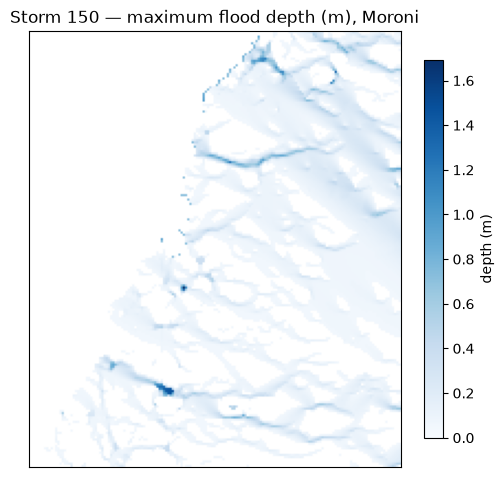

In [5]:
fig, ax = plt.subplots(figsize=(6, 7))
shown = np.where(one_storm >= attrs["extent_threshold_m"], one_storm, np.nan)
im = ax.imshow(shown, cmap="Blues", vmin=0, vmax=float(one_storm.max()))
ax.set_title(f"Storm {STORM} — maximum flood depth (m), {attrs['admin_unit']['name']}")
ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=ax, label="depth (m)", shrink=0.7)
plt.show()

## 2. L'index des tempêtes

La tempête 150 est une position, pas un nom. Le fichier `index.csv` du magasin fait
correspondre chaque position au scénario dont elle provient (`storm_id`) et à son cumul
de pluie (`magnitude_mm`), trié par magnitude — parcourir les positions revient donc à
parcourir la *sévérité*.

La grille est projetée : une cellule vaut simplement `résolution²` et la surface inondée
ne demande aucune correction de latitude. Lire `extent` (un masque mouillé 0/1) coûte
moins cher que lire la profondeur, c'est donc ce qu'utilise le balayage ci-dessous.

200 storms, rainfall totals 0.01 to 1029.7 mm, sorted: True


,storm_index,storm_id,magnitude_mm
0,0,sample_0091,0.01
1,1,sample_0035,0.03
2,2,sample_0003,0.05
100,100,sample_0136,282.68
150,150,sample_0148,422.75
199,199,sample_0199,1029.70


cell 30.57 m -> 935 m² each


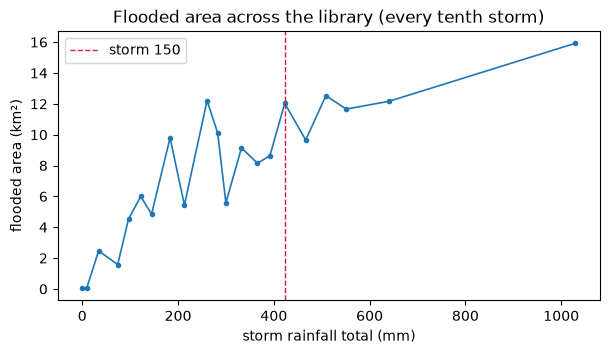

In [6]:
index = pd.read_csv(f"{STORE}/index.csv")
print(f"{len(index)} storms, rainfall totals {index.magnitude_mm.min():g} to "
      f"{index.magnitude_mm.max():g} mm, sorted: {index.magnitude_mm.is_monotonic_increasing}")
display(index.iloc[[0, 1, 2, 100, 150, 199]])

# Grille projetée : la cellule est en mètres carrés, aucun cos(latitude) nulle part.
cell_m2 = attrs["transform"][0] ** 2
print(f"cell {attrs['transform'][0]:.2f} m -> {cell_m2:,.0f} m² each")

sample = list(range(0, 200, 10)) + [199]
extent = group["extent"]
area_km2 = [np.asarray(extent[i]).sum() * cell_m2 / 1e6 for i in sample]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(index.magnitude_mm[sample], area_km2, marker="o", ms=3, lw=1.2)
ax.axvline(index.magnitude_mm[STORM], color="crimson", ls="--", lw=1, label=f"storm {STORM}")
ax.set_xlabel("storm rainfall total (mm)"); ax.set_ylabel("flooded area (km²)")
ax.set_title("Flooded area across the library (every tenth storm)")
ax.legend(); plt.show()

La courbe ne part pas de zéro. Les tempêtes les plus sèches de la bibliothèque portent
un cumul de pluie de quelques centièmes de millimètre et montrent tout de même une
petite emprise permanente — il s'agit de l'**eau permanente** de Moroni, et non d'un
signal d'inondation ; c'est la même ligne de base que la référence de débordement
(`overbank`) de la configuration du site existe pour retirer. C'est exactement pour cela
que l'exercice 3 lit les rasters `pluvial_overbank`. Surveillez ce phénomène chaque fois
que le bas de gamme d'une bibliothèque paraît plus humide qu'il ne devrait.

## 3. Les bâtiments et les routes de Moroni

Les données d'exposition proviennent du geopackage des récepteurs IBF pour la **Grande
Comore** — 131 219 bâtiments et 4 784 tronçons de route, avec les quatre probabilités de
dépassement de l'exercice 3 déjà attachées. Un seul fichier couvre les 29 communes de
l'île : la lecture est donc filtrée sur le code de commune avant que quoi que ce soit ne
sorte du fichier.

Lire un geopackage de 47 Mo directement en HTTPS passe par `/vsicurl` de GDAL, qui
effectue des requêtes par plage une fois par couche ; le télécharger une bonne fois est
bien plus rapide.

In [7]:
import os
import tempfile
import urllib.request
from pathlib import Path

import pyogrio


def cached(url):
    """Télécharge une seule fois dans le dossier temporaire et renvoie le chemin local.

    Le transfert atterrit sur un nom provisoire et n'est déplacé à sa place qu'une fois
    terminé : un téléchargement interrompu ne peut donc pas laisser un fichier tronqué
    en cache sous le vrai nom -- GDAL signale alors "database disk image is malformed"
    à chaque exécution ultérieure, et le supprimer à la main est le seul remède.
    """
    path = Path(tempfile.gettempdir()) / url.rsplit("/", 1)[-1]
    if not path.exists():
        fd, staged = tempfile.mkstemp(dir=path.parent, prefix=f"{path.name}.", suffix=".part")
        os.close(fd)
        try:
            urllib.request.urlretrieve(url, staged)
            os.replace(staged, path)
        finally:
            Path(staged).unlink(missing_ok=True)
    return path


source = cached(FEATURES)
LAYERS = {
    "building": ("buildings",
                 ["feature_id", "subtype", "residential_class", "critical",
                  "final_area_weight", "population_per_building", "building_area_m2"]),
    "road": ("roads", ["feature_id", "road_class", "road_length_m"]),
}

parts = []
for type_, (layer, columns) in LAYERS.items():
    part = pyogrio.read_dataframe(source, layer=layer, columns=columns,
                                  where=f"ADM3_PCODE = '{PCODE}'", use_arrow=True)
    part["type"] = type_
    parts.append(part)
features = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), crs=parts[0].crs)

# Une route n'a pas de population et un bâtiment pas de longueur : on remplit pour que
# chaque ligne se somme.
for col in ["population_per_building", "building_area_m2", "road_length_m"]:
    features[col] = features[col].fillna(0.0)

print(f"{len(features):,} features in {attrs['admin_unit']['name']}  |  "
      f"CRS {features.crs.to_string()}")
print(features["type"].value_counts().to_string())
print()
features[["type", "subtype", "population_per_building", "building_area_m2", "road_length_m"]].head(3)

25,272 features in Moroni  |  CRS EPSG:5629
type
building    24497
road          775



,type,subtype,population_per_building,building_area_m2,road_length_m
0,building,None,2.92,83.88,0.0
1,building,None,0.51,14.60,0.0
2,building,None,1.67,48.03,0.0


`population_per_building` est une estimation **par bâtiment**, et non un décompte de
recensement : la population communale répartie sur ses bâtiments au prorata de la
surface bâtie, ce que consigne `final_area_weight`. Le bon contrôle sur un champ
désagrégé est qu'il se resomme au total dont il provient — et c'est bien le cas ici, à
une erreur d'arrondi près par rapport au tableau communal livré avec le cycle.

Ce contrôle mérite d'être fait à chaque fois. Une colonne de population qui serait en
réalité un *total* répété sur chaque ligne se sommera en un chiffre énorme et tout à
fait plausible ; le paquet d'Antigua-et-Barbuda livre exactement ce piège à côté de la
vraie colonne.

In [8]:
buildings = features[features["type"] == "building"]
communes = pd.read_csv(f"{CYCLE_ROOT}/ibf/communes_{CYCLE}.csv")
official = communes.loc[communes.ADM3_PCODE == PCODE, "population"].iloc[0]

print(f"sum of population_per_building : {buildings.population_per_building.sum():>12,.0f}")
print(f"commune population, communes_{CYCLE}.csv : {official:>12,.0f}")
print(f"sum of road_length_m           : {features.road_length_m.sum() / 1000:>12,.1f} km")
print(f"rd_len_m from the same table   : {communes.loc[communes.ADM3_PCODE == PCODE, 'rd_len_m'].iloc[0] / 1000:>12,.1f} km")

sum of population_per_building :       69,669
commune population, communes_20240427.000000.csv :       69,668
sum of road_length_m           :         82.5 km
rd_len_m from the same table   :         82.5 km


## 4. Échantillonner la profondeur sur chaque entité

Nous voulons, pour chaque bâtiment, **la hauteur d'eau maximale sur son emprise**. C'est
la lecture conservatrice, et elle correspond à la façon dont les probabilités IBF de
l'exercice 3 ont été échantillonnées : les deux produits restent donc comparables.

Le faire entité par entité serait lent, et le raccourci habituel — graver une fois
l'identifiant de chaque entité dans une grille, puis relire les profondeurs par
identifiant — ne fonctionne pas ici. À 30 m, une cellule est plus grande que la plupart
des bâtiments de Moroni, et de nombreux bâtiments partagent une même cellule : graver
les identifiants ne conserve que le dernier et perd silencieusement les autres. La
grille est grossière par rapport aux entités, l'échantillonnage doit donc admettre
**plusieurs entités par cellule**.

On construit plutôt une fois pour toutes la liste des paires (entité, cellule) :

1. Pour chaque entité, prendre les cellules que couvre son rectangle englobant — une
   poignée chacune.
2. Ne garder que les paires où l'entité touche réellement la cellule. C'est un test
   d'intersection vectorisé : un seul appel, pas 25 000.
3. Pour chaque tempête, prendre la profondeur maximale par entité sur ses paires avec
   `np.maximum.at`, en une seule passe sur les paires.

Seule l'étape 3 dépend de la tempête : les étapes 1 et 2 se paient une fois et servent
pour les 200. La reprojection ci-dessous ne fait rien — récepteurs et magasin sont tous
deux en EPSG:5629, car rien dans le paquet des Comores n'est une copie reprojetée — mais
elle est conservée, car rien dans les données ne le garantit et une incohérence
silencieuse placerait toutes les entités hors de la grille.

In [9]:
import shapely

zarr_transform = rasterio.Affine(*attrs["transform"])
rows, cols = attrs["grid_shape"]
features = features.to_crs(attrs["crs"])

# 1. Les cellules couvertes par le rectangle englobant de chaque entité. La ligne 0 est
#    le bord supérieur et la hauteur de cellule `e` est négative : la première ligne
#    vient donc du y *maximum*.
a, _, x0, _, e, y0 = zarr_transform[:6]
minx, miny, maxx, maxy = features.geometry.bounds.to_numpy().T
c0 = np.clip(np.floor((minx - x0) / a).astype(int), 0, cols - 1)
c1 = np.clip(np.floor((maxx - x0) / a).astype(int), 0, cols - 1)
r0 = np.clip(np.floor((maxy - y0) / e).astype(int), 0, rows - 1)
r1 = np.clip(np.floor((miny - y0) / e).astype(int), 0, rows - 1)

n_cells = (r1 - r0 + 1) * (c1 - c0 + 1)
feature_idx = np.repeat(np.arange(len(features)), n_cells)
# Position de chaque candidat dans la fenêtre de son entité, déroulée ligne par ligne.
within = np.arange(n_cells.sum()) - np.repeat(np.cumsum(n_cells) - n_cells, n_cells)
width = np.repeat(c1 - c0 + 1, n_cells)
row = np.repeat(r0, n_cells) + within // width
col = np.repeat(c0, n_cells) + within % width

# 2. Garder les paires où l'entité touche réellement la cellule.
cell_boxes = shapely.box(x0 + col * a, y0 + (row + 1) * e, x0 + (col + 1) * a, y0 + row * e)
touches = shapely.intersects(features.geometry.to_numpy()[feature_idx], cell_boxes)
feature_idx, cell_idx = feature_idx[touches], (row * cols + col)[touches]

sampled = np.unique(feature_idx)
print(f"{len(feature_idx):,} (feature, cell) pairs kept from {n_cells.sum():,} candidates")
print(f"{len(sampled):,} of {len(features):,} features touch at least one cell "
      f"({100 * len(sampled) / len(features):.1f}%)")
print(f"{len(np.unique(cell_idx)):,} of {rows * cols:,} cells carry a feature; "
      f"the busiest carries {np.bincount(cell_idx).max():,}")

47,585 (feature, cell) pairs kept from 54,135 candidates
25,272 of 25,272 features touch at least one cell (100.0%)
9,459 of 33,462 cells carry a feature; the busiest carries 23


Cette dernière ligne est le contrôle à exécuter dès qu'une méthode d'échantillonnage
rencontre une nouvelle grille. Une cellule portant des dizaines de bâtiments est
précisément le cas qu'une rastérisation par gravure d'identifiants ne sait pas
représenter : elle en garde un et jette les autres, sans rien signaler. Les notebooks du
Guatemala gravent des identifiants et ne perdent rien, parce que là-bas les cellules font
5 m et qu'un bâtiment en couvre plusieurs. Même code, grille différente, réponse
différente.

In [10]:
def feature_max_depth(storm_index):
    """Hauteur d'eau maximale sur l'emprise propre de chaque entité, en mètres."""
    layer = np.asarray(depth[storm_index], dtype="float32").ravel()
    # Toute valeur non finie ou négative signifie « pas d'eau », pas une profondeur.
    layer = np.where(np.isfinite(layer) & (layer > 0), layer, 0.0)

    per_feature = np.zeros(len(features), dtype="float32")
    np.maximum.at(per_feature, feature_idx, layer[cell_idx])   # une seule passe sur les paires
    return per_feature


depths = feature_max_depth(STORM)
print(f"storm {STORM}: {int((depths >= attrs['extent_threshold_m']).sum()):,} features touched by water")
print(f"  deepest single feature: {depths.max():.2f} m")

storm 150: 16,257 features touched by water
  deepest single feature: 1.69 m


## 5. Les tranches de profondeur

On regroupe maintenant les profondeurs en tranches. Ce sont les tranches qu'utilisent les
plugins du tableau de bord — des nombres ronds choisis pour que chacune se lise sans
légende : à peu près la cheville, le genou, et au-dessus de la tête. Le plancher de
0,05 m est l'`extent_threshold_m` propre au magasin, et non un nombre inventé.

La tranche supérieure est là où les Comores diffèrent des pays voisins. Parce que la
profondeur est stockée en mètres flottants plutôt que comprimée sur un octet, « 2 m ou
plus » est ici une vraie tranche et non un artefact d'un plafond à 2,55 m. Qu'elle soit
*peuplée* dépend de la tempête.

L'affectation se fait en ordre **croissant**, les affectations ultérieures l'emportant,
de sorte que chaque entité finisse dans la tranche la plus profonde qu'elle atteint.

In [11]:
DEPTH_BANDS = [          # (valeur de classe, couleur, borne inférieure en mètres)
    (1, "green", 0.05),
    (2, "yellow", 0.30),
    (3, "red", 1.00),
    (4, "purple", 2.00),
]
BAND_LABEL = {1: "0.05 - 0.3 m", 2: "0.3 - 1 m", 3: "1 - 2 m", 4: "2 m or more"}


def classify_depth(values):
    band = np.zeros(len(values), dtype="uint8")     # 0 = sec
    for value, _colour, floor in DEPTH_BANDS:
        band[values >= floor] = value               # la tranche la plus profonde l'emporte
    return band


features["depth_m"] = depths
features["band"] = classify_depth(depths)
features["level"] = features.band.map(BAND_LABEL)

pd.crosstab(features["band"].map({0: "dry", **BAND_LABEL}), features["type"]).reindex(["dry", *BAND_LABEL.values()], fill_value=0)

type,building,road
band,,
dry,8757,258
0.05 - 0.3 m,14242,429
0.3 - 1 m,1404,82
1 - 2 m,94,6
2 m or more,0,0


> ⚠️ **Classez avant d'arrondir.** Si vous arrondissez d'abord les profondeurs à 2
> décimales et que vous classez *ensuite*, une entité à 0,0455 m est arrondie à 0,05 et se
> trouve promue dans la tranche mouillée. C'est une question d'affichage qui modifie
> silencieusement la réponse. N'arrondissez que ce que vous affichez.

## 6. Le tableau d'impact

La tranche la plus profonde d'abord, pour que le pire cas se lise en premier, avec un
total sur l'ensemble des entités touchées. La part de population est rapportée à la
commune : la somme de `population_per_building` sur tous les bâtiments de Moroni, que la
section 3 a confrontée au chiffre indiqué par le tableau communal du cycle lui-même.

In [12]:
TOTAL_POPULATION = buildings.population_per_building.sum()     # tous les bâtiments de la commune
print(f"{attrs['admin_unit']['name']} population across all buildings: {TOTAL_POPULATION:,.0f}")


def impact_row(name, group):
    in_band = group[group["type"] == "building"]
    return {
        "Depth": name,
        "Buildings": f"{len(in_band):,}",
        "Population": f"{group.population_per_building.sum():,.0f}",
        "Area (m²)": f"{group.building_area_m2.sum():,.0f}",
        "Roads (km)": f"{group.road_length_m.sum() / 1000:,.1f}",
        "% of population": f"{100 * group.population_per_building.sum() / TOTAL_POPULATION:.2f}%",
    }


affected = features[features.band > 0]
# Attention : pas `rows` -- ce nom contient déjà la hauteur de la grille.
table_rows = [impact_row(BAND_LABEL[v], affected[affected.band == v]) for v, _c, _f in reversed(DEPTH_BANDS)]
table_rows.append(impact_row("TOTAL affected", affected))

pd.DataFrame(table_rows).set_index("Depth")

Moroni population across all buildings: 69,669


,Buildings,Population,Area (m²),Roads (km),% of population
Depth,,,,,
2 m or more,0,0,0,0.0,0.00%
1 - 2 m,94,218,"6,272",0.8,0.31%
0.3 - 1 m,"1,404","4,982","153,001",13.8,7.15%
0.05 - 0.3 m,"14,242","40,285","1,242,487",50.5,57.82%
TOTAL affected,"15,740","45,486","1,401,760",65.1,65.29%


## 7. La cartographie

Les entités touchées, colorées par tranche de profondeur, tracées par-dessus le raster de
profondeur.

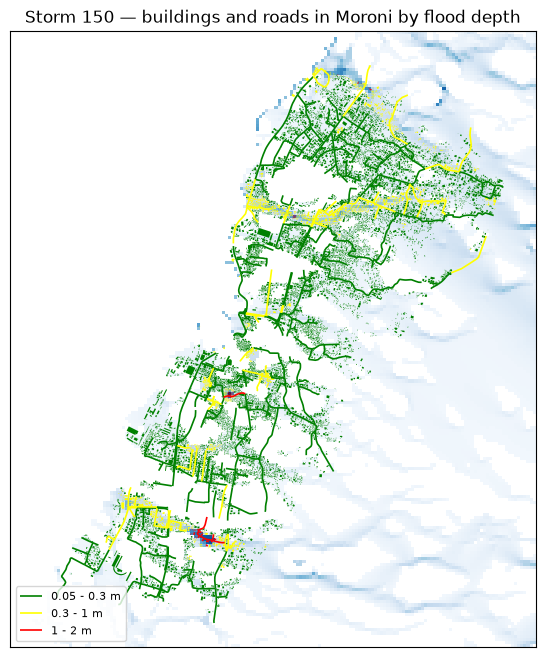

In [13]:
fig, ax = plt.subplots(figsize=(7, 8))
left, bottom, right, top = rasterio.transform.array_bounds(rows, cols, zarr_transform)
ax.imshow(shown, cmap="Blues", vmin=0, vmax=float(one_storm.max()),
          extent=(left, right, bottom, top))

for value, colour, _floor in DEPTH_BANDS:
    subset = features[features.band == value]
    if not subset.empty:
        subset.plot(ax=ax, color=colour, linewidth=1.2, label=BAND_LABEL[value])

ax.set_title(f"Storm {STORM} — buildings and roads in {attrs['admin_unit']['name']} by flood depth")
ax.set_xticks([]); ax.set_yticks([])
handles, labels = ax.get_legend_handles_labels()        # polygones et lignes partagent une étiquette
unique = dict(zip(labels, handles))
ax.legend(unique.values(), unique.keys(), loc="lower left", fontsize=8)
plt.show()

Seules les entités qui atteignent une tranche sont dessinées. Les entités sèches sont
largement majoritaires et n'ajoutent rien qu'un fond de carte ne montre déjà — les écarter
réduit aussi la charge utile de dizaines de milliers d'entités à quelques milliers, ce
qui compte lorsqu'elle est rechargée à chaque changement de tempête.

## 8. L'impact à l'échelle de la bibliothèque

La section 4 a payé l'appariement une fois pour toutes. En le réutilisant, échantillonner
une autre tempête coûte une lecture de chunk et une passe sur les paires : balayer la
bibliothèque est donc bon marché. Comme les magnitudes sont de vrais cumuls de pluie,
l'axe des x ci-dessous est en millimètres et veut dire ce qu'il dit.

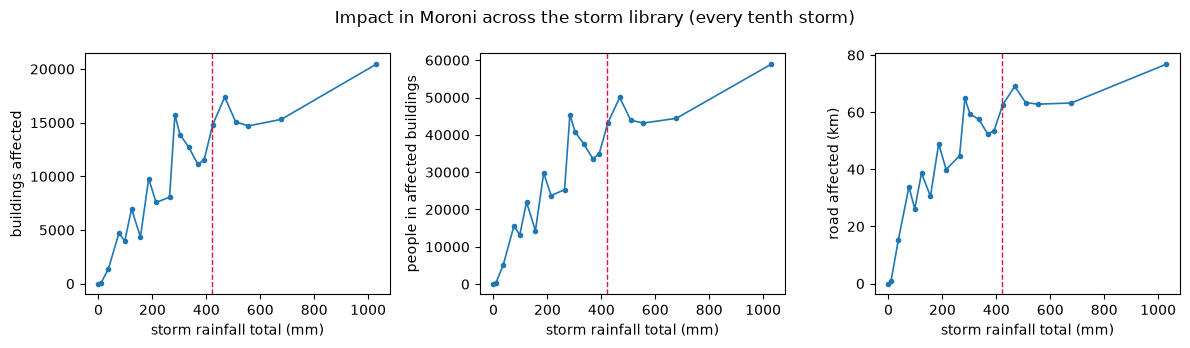

In [14]:
sweep = list(range(1, 200, 10)) + [199]
records = []
for i in sweep:
    band = classify_depth(feature_max_depth(i))
    hit = features[band > 0]
    records.append({"storm": i, "magnitude_mm": index.magnitude_mm[i],
                    "buildings": int((hit["type"] == "building").sum()),
                    "population": hit.population_per_building.sum(),
                    "roads_km": hit.road_length_m.sum() / 1000})
across = pd.DataFrame(records).set_index("storm")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, col, label in zip(axes, ["buildings", "population", "roads_km"],
                          ["buildings affected", "people in affected buildings", "road affected (km)"]):
    ax.plot(across.magnitude_mm, across[col], marker="o", ms=3, lw=1.2)
    ax.axvline(index.magnitude_mm[STORM], color="crimson", ls="--", lw=1)
    ax.set_xlabel("storm rainfall total (mm)"); ax.set_ylabel(label)
fig.suptitle(f"Impact in {attrs['admin_unit']['name']} across the storm library (every tenth storm)")
fig.tight_layout(); plt.show()

Les courbes ne sont pas monotones. La bibliothèque est triée par cumul de pluie moyen sur
la commune, mais l'emprise inondée dépend de l'*endroit* de la commune où la pluie est
tombée et de sa vitesse : un cumul plus élevé ne garantit donc pas davantage de bâtiments
sous l'eau. La magnitude ordonne la bibliothèque ; elle n'ordonne pas l'impact. C'est
pourquoi la prévision apparie un membre à une tempête par le cumul, puis lit l'impact sur
la carte de profondeur, jamais sur la magnitude.

## 9. De la bibliothèque à la prévision : reconstruire le raster de l'exercice 3

Un cycle de prévision ne calcule pas de nouvelles cartes d'inondation. Chacun de ses 50
membres pluviométriques a un cumul sur la commune ; le membre est apparié à une tempête
de la bibliothèque, et la carte de profondeur de cette tempête tient lieu de celle du
membre. La **P(profondeur ≥ 30 cm)** en une cellule est alors la part des 50 membres dont
la tempête appariée inonde cette cellule jusqu'à 30 cm — ce que contiennent les rasters de
probabilité de l'exercice 3.

Pour les Comores, cela peut être vérifié plutôt qu'affirmé. Le cycle publie
`member_decisions.csv` **pour cette commune**, et il consigne la tempête à laquelle chaque
membre a été apparié : la reconstruction ci-dessous peut donc être comparée cellule par
cellule au raster `prob_depth_ge_30cm` livré par l'exécution.

La règle d'appariement mérite d'être lue dans les données plutôt que devinée. `p_rule`
indique `pluvial_band` pour chaque membre, et la magnitude de la tempête appariée est
toujours *supérieure ou égale* au cumul du membre — c'est la plus petite tempête de la
bibliothèque qui couvre le membre, un plafond délibérément conservateur. Deviner « la
magnitude la plus proche » ne reproduit qu'environ 60 % des choix.

In [15]:
decisions = pd.read_csv(f"{CYCLE_ROOT}/fim/{UNIT}/stream_sat_stormlab/member_decisions.csv")
print(f"{len(decisions)} forecast members; rainfall totals "
      f"{decisions.total_mm.min():.1f} to {decisions.total_mm.max():.1f} mm")
print(f"matching rules used: {decisions.p_rule.unique().tolist()}")

# La réponse de l'exécution elle-même : p_storm nomme le scénario, index.csv donne sa position.
position_of = dict(zip(index.storm_id, index.storm_index))
decisions["matched_storm"] = decisions.p_storm.map(position_of).astype(int)
print(f"distinct library storms matched: {decisions.matched_storm.nunique()} "
      f"for {len(decisions)} members")

# Lire la règle dans les données plutôt que la supposer.
order = index.magnitude_mm.to_numpy()
ceiling = np.searchsorted(order, decisions.total_mm.to_numpy(), side="left")
nearest_pos = np.clip(np.searchsorted(order, decisions.total_mm.to_numpy()), 1, len(order) - 1)
closer_below = np.abs(order[nearest_pos - 1] - decisions.total_mm) <= np.abs(order[nearest_pos] - decisions.total_mm)
nearest = np.where(closer_below, nearest_pos - 1, nearest_pos)
print(f'  "smallest storm >= member total" reproduces {100 * (ceiling == decisions.matched_storm).mean():.0f}% of the choices')
print(f'  "nearest magnitude"              reproduces {100 * (nearest == decisions.matched_storm).mean():.0f}%')

50 forecast members; rainfall totals 57.3 to 284.7 mm
matching rules used: ['pluvial_band']
distinct library storms matched: 16 for 50 members
  "smallest storm >= member total" reproduces 100% of the choices
  "nearest magnitude"              reproduces 60%


distinct probability values: 34   max 1.00
largest difference from the published raster: 0.000000
cells differing: 0 of 33,462


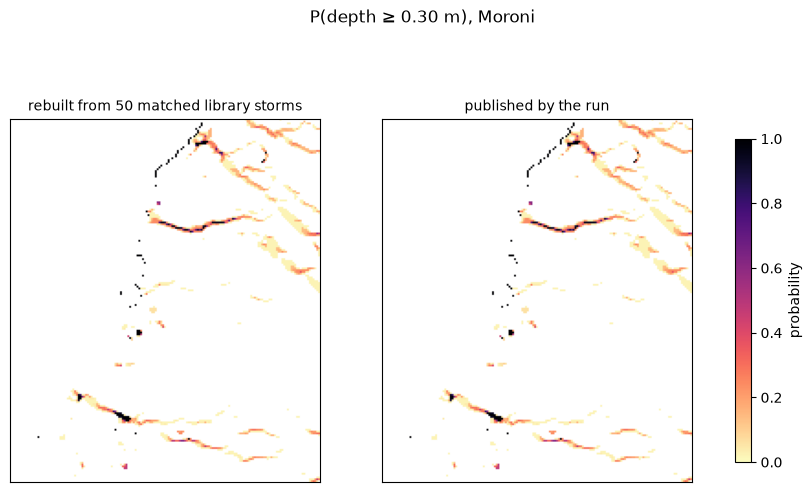

In [16]:
# P(profondeur >= 0,30 m) = part des membres dont la tempête appariée atteint 30 cm à la cellule.
count = np.zeros((rows, cols), dtype="int32")
for i in decisions.matched_storm:
    count += np.asarray(depth[int(i)]) >= 0.30
prob_30 = count / len(decisions)

# L'exécution a livré ce raster. Le reconstruire est le contrôle qui montre que le
# mécanisme ci-dessus est bien celui qui a produit les entrées de l'exercice 3.
published = f"{CYCLE_ROOT}/fim/{UNIT}/stream_sat_stormlab/pluvial/prob_depth_ge_30cm.{CYCLE}.tif"
with rasterio.open(published) as ds:
    delivered = ds.read(1)

difference = np.abs(prob_30 - delivered).max()
print(f"distinct probability values: {len(np.unique(prob_30))}   max {prob_30.max():.2f}")
print(f"largest difference from the published raster: {difference:.6f}")
print(f"cells differing: {int((np.abs(prob_30 - delivered) > 1e-6).sum()):,} of {prob_30.size:,}")

fig, axes = plt.subplots(1, 2, figsize=(11, 6))
for ax, grid, title in zip(axes, [prob_30, delivered],
                           ["rebuilt from 50 matched library storms", "published by the run"]):
    im = ax.imshow(np.where(grid > 0, grid, np.nan), cmap="magma_r", vmin=0, vmax=1)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("P(depth ≥ 0.30 m), Moroni")
fig.colorbar(im, ax=axes, label="probability", shrink=0.7)
plt.show()

Deux enseignements à retenir de cette section :

- **Cinquante membres se réduisent à seize tempêtes distinctes.** Cinq réalisations
  pluviométriques expliquent presque toute la dispersion : la probabilité est donc
  quantifiée — les rasters de l'exercice 3 prennent peu de valeurs distinctes, et c'est
  la raison, non un artefact d'arrondi.
- **La reconstruction est exacte.** Chaque cellule du raster publié est reproduite, ce
  qui signifie que le mécanisme décrit ici *est* le mécanisme, et non une histoire
  plausible à son sujet. Si vous remplacez la règle d'appariement par « la plus proche »,
  l'accord s'effondre, et c'est le moyen le plus rapide de voir à quel point la règle
  compte.

## 10. Construire les plugins « tempête » pour les Comores

Tout ce qui précède s'exécute ici, dans un notebook. Pour le mettre sur un tableau de
bord, le même code doit devenir un **plugin** : un paquet Python installable que
TethysDash découvre tout seul et exécute pour le frontend.

`tgf_wmo_plugins` livre une famille « tempête » — `uffis_storm_card_*`,
`uffis_storm_impact_summary_*`, `uffis_storm_impact_layer_*` — qui réalise les sections 3
à 6 pour l'ensemble du Guatemala. Son URL de magasin, son nombre de tempêtes et ses
étiquettes de magnitude sont des constantes de module propres à ce seul magasin : une
variante Comores consiste donc surtout à les rendre spécifiques au pays et à ajouter un
argument. La liste ci-dessous résume du même coup ce que ce notebook a codé en dur.

### Ce que déclare une variante Comores

| quoi | d'où cela vient |
|---|---|
| l'URL du magasin | `fim_store_{UNIT}_v1.zarr`, section 1 — un par commune |
| le filtre de commune | `ADM3_PCODE = '{PCODE}'`, section 3 |
| la liste déroulante `index` | les positions comme valeurs, `magnitude_mm` d'`index.csv` comme étiquettes |
| les tranches de profondeur | `DEPTH_BANDS`, section 5 — partagées, et significatives jusqu'à 2 m ici |
| le dénominateur de population | `population_per_building` sommé sur la commune, section 6 |

### Découverte — comment l'application le trouve

Un plugin est une classe enregistrée comme **point d'entrée Intake** dans
`pyproject.toml` :

```toml
[project.entry-points."intake.drivers"]
uffis_storm_impact_summary_comoros = "tgf_wmo_plugins.storm_impact:StormImpactSummaryComoros"
uffis_storm_impact_layer_comoros   = "tgf_wmo_plugins.storm_impact:StormImpactLayerComoros"
uffis_storm_card_comoros           = "tgf_wmo_plugins.storm_card:StormCardComoros"
```

La clé doit correspondre au `name` de la classe, sinon l'interface liste un plugin
qu'elle ne peut pas charger.

### La classe — propriétés de découverte, arguments, et une méthode

Les produits comoriens sont francophones, et le français existe déjà dans `STRINGS`
puisque Haïti l'utilise : `LANG = "fr"` ne coûte donc rien.

```python
from tethysapp.tethysdash.plugin_helpers import TethysDashPlugin


class StormImpactSummaryComoros(TethysDashPlugin):

    # ---- découverte : comment l'interface liste et présente ce plugin ----
    LANG = "fr"
    country = "comoros"
    name = "uffis_storm_impact_summary_comoros"    # doit correspondre à la clé du point d'entrée
    label = f"{STRINGS[LANG]['storm_summary_label']} (Comores)"
    group = STRINGS[LANG]["group"]                 # la rubrique sous laquelle il est classé
    tags = ["inondation", "impact", "zarr", "tempête", "tableau", "français"]

    # ---- de quel type de visualisation il s'agit -------------------------
    type = "table"
    # `type` choisit le moteur de rendu du frontend, et dicte donc la forme que run()
    # doit renvoyer. Au choix : table, card, plotly, image, text, variable_input,
    # map, map_layer, custom.

    # ---- ce que l'interface demande de renseigner à l'auteur du tableau de bord ----
    args = {
        "commune": COMMUNE_OPTIONS,   # une liste de {"value", "label"} -> une liste déroulante
        "index": STORM_OPTIONS,       # des positions, étiquetées par magnitude_mm
    }
    # Les *noms* des arguments sont le contrat : ce sont les clés qu'un tableau de bord
    # stocke, donc en renommer un casse silencieusement tous les tableaux de bord qui
    # l'utilisent déjà. Un argument qu'un plugin ne déclare pas est simplement absent à
    # l'exécution -- cela ne lève pas d'erreur, la valeur par défaut est utilisée, et le
    # contrôle semble ne rien faire.

    def run(self):
        """Appelée une fois par requête, et à nouveau dès qu'un argument lié change."""

        commune = self.get_arg("commune", "KM274")
        index = self.get_arg("index", 150)
        # get_arg() lit une valeur configurée. Si l'auteur a lié cet argument à une
        # entrée variable, la référence "${Storm}" est déjà résolue à ce stade --
        # le plugin ne voit jamais la syntaxe de gabarit.

        gdf = banded_features(commune, index)
        # ^ sections 3 à 5 : charger les entités de la commune, échantillonner la hauteur
        #   d'eau maximale sur chaque emprise, attacher une tranche de profondeur.

        # Une `table` renvoie un titre et une liste de dictionnaires de lignes. Les clés
        # deviennent les colonnes, dans l'ordre ; les valeurs sont des chaînes déjà
        # formatées, car la façon dont un nombre doit se lire est une décision que le
        # moteur de rendu ne peut pas prendre.
        return {"title": ..., "data": [{"Profondeur": "...", "Bâtiments": "..."}]}
```

### L'argument de commune est la nouveauté

Les plugins « tempête » existants prennent un seul argument, `index`, parce que le
Guatemala n'a qu'un magasin. Les Comores écrivent un magasin par commune : un second
argument doit donc le sélectionner — la même décision que rencontre l'exercice 3, et elle
devrait être tranchée de la même façon dans les deux, sinon un tableau de bord se
retrouve avec deux contrôles qui veulent dire la même chose et peuvent se contredire.

Cela change aussi ce qui peut être mis en cache. L'appariement (entité, cellule) de la
section 4 est coûteux et indépendant de la tempête : les plugins le mettent donc en cache
— mais il dépend de la *commune*, si bien que la clé de cache doit être la commune, et
non une variable globale au niveau du module.

### Les couches cartographiques implémentent deux méthodes, pas une

Un plugin `map_layer` se voit poser deux questions différentes à deux moments
différents : il y répond donc séparément.

```python
class StormImpactLayerComoros(TethysDashPlugin):
    name = "uffis_storm_impact_layer_comoros"
    type = "map_layer"
    dynamic_map_layer = True     # c'est ce drapeau qui active fetch_features()
    args = {"commune": COMMUNE_OPTIONS, "index": STORM_OPTIONS}

    def run(self):
        """Au moment de la CONFIGURATION. Appelée une fois, quand l'auteur ajoute la couche.

        Renvoie l'*ossature* de la couche, pas ses données : un nom, une liaison à une
        source, des règles de style et une légende. C'est ce qu'appelle le bouton
        « Fetch plugin defaults » de l'éditeur de couches.
        """
        builder = LayerConfigurationBuilder(STRINGS[self.LANG]["storm_layer_name"], "GeoJSON")

        builder.set_plugin_source(self.name, self.received_args)
        # received_args, PAS self.args. self.args est le *schéma* ; la réinvocation à
        # l'exécution a besoin des *valeurs* configurées, y compris toute liaison
        # "${Storm}" qui reste à résoudre à chaque récupération.

        builder.set_style(...)    # règles fondées sur l'attribut `banda`
        builder.set_legend(...)   # ce que la légende de la carte affiche pour cette couche
        return builder.build()

    def fetch_features(self):
        """Au moment de l'EXÉCUTION. Appelée au chargement, puis à chaque changement de `${Storm}`.

        Renvoie du GeoJSON. C'est la seule partie qui se ré-exécute.
        """
        self.send_update("Échantillonnage des profondeurs...", percentage_complete=10)
        # send_update() diffuse la progression vers la tuile par WebSocket, pour qu'un
        # recalcul de quelques secondes paraisse occupé plutôt que cassé.

        gdf = banded_features(self.get_arg("commune", "KM274"), self.get_arg("index", 150))
        return {"type": "FeatureCollection",
                "features": [...],
                "crs": {"type": "name", "properties": {"name": "EPSG:4326"}}}
```

### Une chose que les Comores imposent et que les autres pays n'imposaient pas

Ce `"EPSG:4326"` dans le CRS renvoyé n'est pas décoratif. Les récepteurs et le magasin
sont en **EPSG:5629** (Moznet / UTM zone 38S), et le frontend ne résout qu'EPSG:4326 et
EPSG:3857 sans proj4 — les entités doivent donc être reprojetées avant d'être renvoyées,
sinon la couche se charge et atterrit très loin de l'océan Indien. Le Guatemala
(EPSG:3857) et Antigua-et-Barbuda (EPSG:4326) n'ont jamais eu à y penser.

C'est aussi pourquoi un plugin est la réponse plutôt qu'une simple couche
cartographique. TethysDash peut pointer une couche vectorielle directement sur un
GeoPackage, mais son chargeur n'enregistre au préalable avec proj4 que les zones UTM
WGS84, et 5629 n'en fait pas partie — la même géométrie sous un code d'autorité
différent.

### Les trois plugins construits sur ce type de données

| plugin | `type` | ce que renvoie `run()` |
|---|---|---|
| `uffis_storm_impact_summary_*` | `table` | `{"title", "data": [dicts de lignes]}` — le tableau de la section 6 |
| `uffis_storm_impact_layer_*` | `map_layer` | une ossature de couche ; `fetch_features()` renvoie ensuite le GeoJSON derrière la section 7 |
| `uffis_storm_card_*` | `card` | `{"data": [{"color", "label", "value", "icon"}]}` — les chiffres clés, sans titre |

### Pourquoi la séparation en deux méthodes est rentable

`run()` s'exécute une fois, quand quelqu'un configure le tableau de bord.
`fetch_features()` s'exécute à chaque changement d'une variable liée. Mettre le style et
la légende dans `run()` fait qu'ils sont calculés une fois et stockés avec le tableau de
bord : changer de tempête ne relance donc que la partie qui dépend réellement de la
tempête.

Les trois plugins importent un même module central qui met en cache l'étape indépendante
de la tempête : construire les paires (entité, cellule) se paie une fois par commune et
par processus — section 4 — et changer de tempête relit un chunk et refait une seule
passe sur les paires.

### Pistes à explorer

- Changez `STORM` dans la section 1 et relancez. Les tempêtes 0 à 2 sont la référence
  sèche — ce que vous y voyez est l'eau stagnante permanente de Moroni, et non une
  inondation. La tempête 150 n'atteint jamais la tranche de profondeur supérieure : sur
  les 200, seules sept mettent de l'eau au-dessus de 2 m (la tempête 137, et de 194 à
  199), cette ligne reste donc vide à moins d'en choisir une. La tempête 199 est la plus
  grande de la bibliothèque, à 2,58 m.
- Changez `UNIT` pour une autre commune — `KM271_BambaoYaHari`, `KM283_OichiliYamboini`,
  `KM321_Fomboni` sur Mohéli — et relancez tout le notebook. Rien d'autre n'a besoin de
  changer : la population communale, le fichier de l'île et les décisions des membres en
  découlent tous. Notez qu'au moment de la rédaction, 33 des 55 magasins étaient encore
  en cours de téléversement : une commune peut donc ne pas se résoudre.
- Changez les bornes de `DEPTH_BANDS`. Qu'advient-il du tableau si vous ajoutez une
  tranche « 1,5 m ou plus » ? Faites la même expérience sur un magasin
  d'Antigua-et-Barbuda, où la profondeur est comprimée sur un octet et sature à 2,55 m,
  et voyez quelles tranches cessent de vouloir dire quelque chose.
- La section 4 prend la profondeur **maximale** sur chaque emprise. Essayez la moyenne à
  la place (`np.add.at` et un compteur) et voyez comment le tableau change. Lequel des
  deux chiffres est le plus défendable à donner à un décideur ?
- Dans la section 9, remplacez le `matched_storm` de l'exécution par le tableau `nearest`
  calculé juste à côté et relancez. Le raster publié n'est plus reproduit. À quel point
  le tableau d'impact devient-il faux, et l'auriez-vous remarqué sans la comparaison ?
- Comparez la `band` attribuée par ce notebook au `risk_label` que l'exécution a écrit
  dans le geopackage. Ils répondent à des questions différentes — la profondeur dans une
  tempête, contre la probabilité croisée avec la sévérité sur toute la prévision. Lequel
  a sa place dans une alerte, et lequel dans un briefing ?
- La chaîne comorienne est pluviale uniquement (`hazards_enabled` dans
  `pf_summary.json`). Qu'est-ce qui changerait dans les sections 4 à 6 si un modèle
  insulaire était plus tard exécuté avec un apport fluvial ?